# Semana 2 Encapsulamiento e invariantes

Proteger el estado de Curso y Docente mediante propiedades y operaciones que preservan invariantes, y trasladar el mismo criterio a las tres clases iniciales del hotel.

Identificador S2-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


class Reserva:
    def __init__(self, codigo, entrada, salida):
        self.__codigo = texto(codigo)
        self.__entrada = date.fromisoformat(entrada)
        self.__salida = date.fromisoformat(salida)
        if self.__salida <= self.__entrada:
            raise ValueError("Salida debe ser posterior")
        self.__estado = "REGISTRADA"

    @property
    def codigo(self):
        return self.__codigo

    @property
    def entrada(self):
        return self.__entrada.isoformat()

    @property
    def salida(self):
        return self.__salida.isoformat()

    @property
    def noches(self):
        return (self.__salida - self.__entrada).days

    @property
    def estado(self):
        return self.__estado

    def confirmar(self):
        if self.estado != "REGISTRADA":
            raise RuntimeError("Confirmacion no permitida")
        self.__estado = "CONFIRMADA"

    def anular(self):
        if self.estado == "ANULADA":
            raise RuntimeError("Reserva ya anulada")
        self.__estado = "ANULADA"


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
"""Actividades 1 y 2: invariantes, composición y propiedades calculadas."""

import re
from datetime import date


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Curso:
    # Se sigue el patrón explícito de las plantillas Python y C++ de la guía.
    _PATRON_CODIGO = re.compile(r"[A-Z]{2,4}[0-9]{3}")

    def __init__(self, codigo, nombre, creditos, cupos_maximo):
        self.__inscritos = 0
        if not isinstance(nombre, str) or not nombre.strip():
            raise ValueError("Nombre vacio")
        self.__nombre = nombre
        self.codigo = codigo
        self.creditos = creditos
        self.cupos_maximo = cupos_maximo

    @property
    def nombre(self):
        return self.__nombre

    @property
    def codigo(self):
        return self.__codigo

    @codigo.setter
    def codigo(self, valor):
        if not isinstance(valor, str) or not self._PATRON_CODIGO.fullmatch(valor):
            raise ValueError("Codigo debe tener 2 a 4 letras mayusculas y 3 digitos")
        self.__codigo = valor

    @property
    def creditos(self):
        return self.__creditos

    @creditos.setter
    def creditos(self, valor):
        self.__creditos = entero(valor, 1, 6)

    @property
    def cupos_maximo(self):
        return self.__cupos_maximo

    @cupos_maximo.setter
    def cupos_maximo(self, valor):
        entero(valor, 1, 50)
        if valor < self.__inscritos:
            raise ValueError("Cupos menores que inscritos")
        self.__cupos_maximo = valor

    @property
    def inscritos(self):
        return self.__inscritos

    @property
    def cupos_disponibles(self):
        return self.cupos_maximo - self.inscritos

    @property
    def esta_lleno(self):
        return self.cupos_disponibles == 0

    def inscribir_estudiante(self):
        if self.esta_lleno:
            raise RuntimeError("Curso sin cupos")
        self.__inscritos += 1

    def __str__(self):
        return f"{self.codigo} - {self.nombre} ({self.creditos} cr) [{self.inscritos}/{self.cupos_maximo} inscritos]"


class Docente:
    def __init__(self, dni, nombres, apellidos, correo, fecha_nac):
        if not re.fullmatch(r"[0-9]{8}", dni):
            raise ValueError("DNI invalido")
        if not re.fullmatch(r"[^@\s]+@unap\.edu\.pe", correo):
            raise ValueError("Correo institucional invalido")
        if not nombres.strip() or not apellidos.strip():
            raise ValueError("Nombre vacio")
        if type(fecha_nac) is not date or fecha_nac > date.today():
            raise ValueError("Nacimiento invalido")
        self.__dni, self.__nombres, self.__apellidos = dni, nombres, apellidos
        self.__correo, self.__fecha_nac = correo, fecha_nac
        self.__cursos = []

    @property
    def dni(self):
        return self.__dni

    @property
    def nombre_completo(self):
        return f"{self.__apellidos}, {self.__nombres}"

    def edad_en(self, hoy):
        if hoy < self.__fecha_nac:
            raise ValueError("Referencia anterior al nacimiento")
        return (
            hoy.year
            - self.__fecha_nac.year
            - ((hoy.month, hoy.day) < (self.__fecha_nac.month, self.__fecha_nac.day))
        )

    @property
    def edad(self):
        return self.edad_en(date.today())

    @property
    def cursos(self):
        return tuple(self.__cursos)

    @property
    def total_creditos(self):
        return sum(c.creditos for c in self.__cursos)

    @property
    def total_inscritos(self):
        return sum(c.inscritos for c in self.__cursos)

    def asignar_curso(self, curso):
        if any(c.codigo == curso.codigo for c in self.__cursos):
            raise ValueError("Curso duplicado")
        if len(self.__cursos) >= 3:
            raise RuntimeError("Maximo tres cursos")
        self.__cursos.append(curso)


def demo():
    c = Curso("SIS206", "POO II", 4, 30)
    for _ in range(3):
        c.inscribir_estudiante()
    d = Docente("12345678", "Ana", "Mamani", "ana@unap.edu.pe", date(1980, 5, 14))
    d.asignar_curso(c)
    return [
        f"CURSO={c.codigo}",
        f"LIBRES={c.cupos_disponibles}",
        f"CREDITOS={d.total_creditos}",
        f"INSCRITOS={d.total_inscritos}",
        f"EDAD_REFERENCIA={d.edad_en(date(2026, 10, 18))}",
    ]


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};

class Reserva {
    std::string codigo_, entrada_, salida_, estado_ = "REGISTRADA";

  public:
    Reserva(std::string codigo, std::string entrada, std::string salida)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)) {
        textoValido(codigo_);
        if (ordinal(salida_) <= ordinal(entrada_)) {
            throw std::invalid_argument("Salida debe ser posterior");
        }
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::string &estado() const noexcept {
        return estado_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    void confirmar() {
        if (estado_ != "REGISTRADA") {
            throw std::runtime_error("Confirmacion no permitida");
        }
        estado_ = "CONFIRMADA";
    }
    void anular() {
        if (estado_ == "ANULADA") {
            throw std::runtime_error("Reserva ya anulada");
        }
        estado_ = "ANULADA";
    }
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include "hotel_base.hpp"
#include "solucion.hpp"
int main() {
    Pruebas t;
    t.caso("curso valido", [] {
        const Curso c("SIS206", "POO", 4, 30);
        exigir(c.getCreditos() == 4);
    });
    t.caso("codigo", [] { debeFallar<std::invalid_argument>([] { Curso c("X9", "X", 4, 30); }); });
    t.caso("creditos",
           [] { debeFallar<std::invalid_argument>([] { Curso c("SIS206", "X", 0, 30); }); });
    t.caso("cupos",
           [] { debeFallar<std::invalid_argument>([] { Curso c("SIS206", "X", 4, 51); }); });
    t.caso("lleno", [] {
        Curso c("SIS206", "X", 4, 1);
        c.inscribirEstudiante();
        debeFallar([&] { c.inscribirEstudiante(); });
        exigir(c.estaLleno());
    });
    t.caso("reducir sin romper", [] {
        Curso c("SIS206", "X", 4, 3);
        c.inscribirEstudiante();
        c.inscribirEstudiante();
        debeFallar([&] { c.setCuposMaximo(1); });
        exigir(c.getCuposMaximo() == 3);
    });
    t.caso("dni",
           [] { debeFallar([] { Docente d("123", "A", "B", "a@unap.edu.pe", "1980-05-14"); }); });
    t.caso("correo", [] {
        debeFallar([] { Docente d("12345678", "A", "B", "a@unap.edu.pe.evil", "1980-05-14"); });
    });
    t.caso("edad", [] {
        Docente d("12345678", "A", "B", "a@unap.edu.pe", "1980-05-14");
        exigir(d.edadEn("2026-05-13") == 45 && d.edadEn("2026-05-14") == 46);
    });
    t.caso("datos derivados", [] {
        Docente d("12345678", "A", "B", "a@unap.edu.pe", "1980-05-14");
        auto c = std::make_shared<Curso>("SIS206", "X", 4, 30);
        d.asignarCurso(c);
        c->setCreditos(6);
        c->inscribirEstudiante();
        exigir(d.totalCreditos() == 6 && d.totalInscritos() == 1);
    });
    t.caso("limite docente", [] {
        Docente d("12345678", "A", "B", "a@unap.edu.pe", "1980-05-14");
        for (auto s : {"SIS206", "SIS207", "SIS208"}) {
            d.asignarCurso(std::make_shared<Curso>(s, "X", 4, 30));
        }
        debeFallar([&] { d.asignarCurso(std::make_shared<Curso>("SIS209", "X", 4, 30)); });
    });
    t.caso("huesped", [] {
        Huesped h("H1", "Ana", "12345678");
        debeFallar([&] { h.setDocumento("12"); });
        exigir(h.documento() == "12345678");
    });
    t.caso("habitacion", [] {
        Habitacion h(101, "Doble", 2, 100);
        h.alojar(2);
        debeFallar([&] { h.setCapacidad(1); });
        exigir(h.plazasLibres() == 0);
    });
    t.caso("tarifa no finita",
           [] { debeFallar([] { Habitacion h(101, "Doble", 2, std::nan("")); }); });
    t.caso("reserva", [] {
        Reserva r("R1", "2026-10-18", "2026-10-20");
        exigir(r.noches() == 2);
        r.confirmar();
        r.anular();
        debeFallar([&] { r.confirmar(); });
    });
    t.caso("fecha inexistente",
           [] { debeFallar([] { Reserva r("R1", "2026-02-28", "2026-02-30"); }); });
    return t.terminar();
}


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "comun.hpp"

class Curso {
    std::string codigo_, nombre_;
    int creditos_ = 1, cuposMaximo_ = 1, inscritos_ = 0;

  public:
    Curso(const std::string &codigo, std::string nombre, int creditos, int cupos)
        : nombre_(std::move(nombre)) {
        textoValido(nombre_);
        setCodigo(codigo);
        setCreditos(creditos);
        setCuposMaximo(cupos);
    }
    const std::string &getCodigo() const noexcept {
        return codigo_;
    }
    const std::string &getNombre() const noexcept {
        return nombre_;
    }
    int getCreditos() const noexcept {
        return creditos_;
    }
    int getInscritos() const noexcept {
        return inscritos_;
    }
    int getCuposMaximo() const noexcept {
        return cuposMaximo_;
    }
    int cuposDisponibles() const noexcept {
        return cuposMaximo_ - inscritos_;
    }
    bool estaLleno() const noexcept {
        return cuposDisponibles() == 0;
    }
    void setCodigo(const std::string &codigo) {
        if (!std::regex_match(codigo, std::regex("[A-Z]{2,4}[0-9]{3}"))) {
            throw std::invalid_argument("Codigo invalido");
        }
        codigo_ = codigo;
    }
    void setCreditos(int valor) {
        if (valor < 1 || valor > 6) {
            throw std::invalid_argument("Creditos fuera de rango");
        }
        creditos_ = valor;
    }
    void setCuposMaximo(int valor) {
        if (valor < 1 || valor > 50 || valor < inscritos_) {
            throw std::invalid_argument("Cupos invalidos");
        }
        cuposMaximo_ = valor;
    }
    void inscribirEstudiante() {
        if (estaLleno()) {
            throw std::runtime_error("Curso sin cupos");
        }
        ++inscritos_;
    }
};

class Docente {
    std::string dni_, nombres_, apellidos_, correo_, nacimiento_;
    std::vector<std::shared_ptr<Curso>> cursos_;

  public:
    Docente(std::string dni, std::string nombres, std::string apellidos, std::string correo,
            std::string nacimiento)
        : dni_(std::move(dni)), nombres_(std::move(nombres)), apellidos_(std::move(apellidos)),
          correo_(std::move(correo)), nacimiento_(std::move(nacimiento)) {
        if (!std::regex_match(dni_, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        if (!std::regex_match(correo_, std::regex("[^@\\s]+@unap\\.edu\\.pe"))) {
            throw std::invalid_argument("Correo invalido");
        }
        textoValido(nombres_);
        textoValido(apellidos_);
        if (ordinal(nacimiento_) > ordinal(hoyISO())) {
            throw std::invalid_argument("Nacimiento futuro");
        }
    }
    std::string nombreCompleto() const {
        return apellidos_ + ", " + nombres_;
    }
    int edadEn(const std::string &hoy) const {
        if (ordinal(hoy) < ordinal(nacimiento_)) {
            throw std::invalid_argument("Referencia invalida");
        }
        return std::stoi(hoy.substr(0, 4)) - std::stoi(nacimiento_.substr(0, 4)) -
               (hoy.substr(5) < nacimiento_.substr(5));
    }
    int edad() const {
        return edadEn(hoyISO());
    }
    int totalCreditos() const {
        int total = 0;
        for (const auto &curso : cursos_) {
            total += curso->getCreditos();
        }
        return total;
    }
    int totalInscritos() const {
        int total = 0;
        for (const auto &curso : cursos_) {
            total += curso->getInscritos();
        }
        return total;
    }
    void asignarCurso(std::shared_ptr<Curso> curso) {
        if (!curso) {
            throw std::invalid_argument("Curso nulo");
        }
        for (const auto &actual : cursos_) {
            if (actual->getCodigo() == curso->getCodigo()) {
                throw std::invalid_argument("Curso duplicado");
            }
        }
        if (cursos_.size() >= 3) {
            throw std::runtime_error("Maximo tres cursos");
        }
        cursos_.push_back(std::move(curso));
    }
};

inline void demo() {
    auto curso = std::make_shared<Curso>("SIS206", "POO II", 4, 30);
    for (int i = 0; i < 3; ++i) {
        curso->inscribirEstudiante();
    }
    Docente docente("12345678", "Ana", "Mamani", "ana@unap.edu.pe", "1980-05-14");
    docente.asignarCurso(curso);
    std::cout << "CURSO=" << curso->getCodigo() << "\nLIBRES=" << curso->cuposDisponibles()
              << "\nCREDITOS=" << docente.totalCreditos()
              << "\nINSCRITOS=" << docente.totalInscritos()
              << "\nEDAD_REFERENCIA=" << docente.edadEn("2026-10-18") << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
from datetime import date
from python.solucion import Curso, Docente
from python.hotel_base import Huesped, Habitacion, Reserva


class ContratosSemana2(unittest.TestCase):
    def curso(self):
        return Curso("SIS206", "POO", 4, 3)

    def docente(self):
        return Docente("12345678", "Ana", "Mamani", "ana@unap.edu.pe", date(1980, 5, 14))

    def test_constructor_valido(self):
        self.assertEqual(self.curso().creditos, 4)

    def test_codigos_invalidos(self):
        for codigo in ["X9", "sis206", "SIS206x", "SIS１２３"]:
            with self.subTest(codigo=codigo), self.assertRaises(ValueError):
                Curso(codigo, "POO", 4, 30)

    def test_creditos_fronteras(self):
        for credito in [1, 6]:
            self.assertEqual(Curso("AB123", "X", credito, 30).creditos, credito)
        for credito in [0, 7, True, 1.5]:
            with self.subTest(c=credito), self.assertRaises(ValueError):
                Curso("SIS206", "X", credito, 30)

    def test_cupos_fronteras(self):
        for cupos in [0, 51]:
            with self.subTest(c=cupos), self.assertRaises(ValueError):
                Curso("SIS206", "X", 4, cupos)

    def test_curso_lleno(self):
        c = self.curso()
        for _ in range(3):
            c.inscribir_estudiante()
        with self.assertRaises(RuntimeError):
            c.inscribir_estudiante()
        self.assertTrue(c.esta_lleno)

    def test_no_reducir_cupos_bajo_inscritos(self):
        c = self.curso()
        c.inscribir_estudiante()
        c.inscribir_estudiante()
        with self.assertRaises(ValueError):
            c.cupos_maximo = 1
        self.assertEqual(c.cupos_maximo, 3)

    def test_propiedades_solo_lectura(self):
        c = self.curso()
        for attr in ["inscritos", "cupos_disponibles", "esta_lleno"]:
            with self.subTest(attr=attr), self.assertRaises(AttributeError):
                setattr(c, attr, 99)

    def test_name_mangling(self):
        with self.assertRaises(AttributeError):
            getattr(self.curso(), "__codigo")

    def test_dni_correo(self):
        for dni, correo in [("123", "ana@unap.edu.pe"), ("12345678", "ana@unap.edu.pe.evil")]:
            with self.subTest(dni=dni), self.assertRaises(ValueError):
                Docente(dni, "Ana", "Mamani", correo, date(1980, 5, 14))

    def test_edad_antes_y_en_cumpleanos(self):
        d = self.docente()
        self.assertEqual(d.edad_en(date(2026, 5, 13)), 45)
        self.assertEqual(d.edad_en(date(2026, 5, 14)), 46)

    def test_propiedades_derivadas_cambian_con_curso(self):
        d, c = self.docente(), self.curso()
        d.asignar_curso(c)
        c.creditos = 6
        c.inscribir_estudiante()
        self.assertEqual((d.total_creditos, d.total_inscritos), (6, 1))

    def test_asignacion_limite_tres_y_duplicado(self):
        d = self.docente()
        for n in [206, 207, 208]:
            d.asignar_curso(Curso(f"SIS{n}", "X", 4, 30))
        with self.assertRaises(RuntimeError):
            d.asignar_curso(Curso("SIS209", "X", 4, 30))
        with self.assertRaises(ValueError):
            d.asignar_curso(d.cursos[0])

    def test_huesped_documento(self):
        h = Huesped("H1", "Ana", "12345678")
        with self.assertRaises(ValueError):
            h.actualizar_documento("12")
        self.assertEqual(h.documento, "12345678")

    def test_habitacion_capacidad(self):
        h = Habitacion(101, "Doble", 2, 100)
        h.alojar(2)
        with self.assertRaises(ValueError):
            h.capacidad = 1
        self.assertEqual(h.plazas_libres, 0)

    def test_habitacion_tarifa(self):
        with self.assertRaises(ValueError):
            Habitacion(101, "Doble", 2, float("nan"))

    def test_reserva_fechas_y_negocio(self):
        r = Reserva("R1", "2026-10-18", "2026-10-20")
        self.assertEqual(r.noches, 2)
        r.confirmar()
        r.anular()
        with self.assertRaises(RuntimeError):
            r.confirmar()

    def test_reserva_fecha_invalida(self):
        for fin in ["2026-10-18", "2026-02-30"]:
            with self.subTest(fin=fin), self.assertRaises(ValueError):
                Reserva("R1", "2026-10-18", fin)


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


CURSO=SIS206
LIBRES=27
CREDITOS=4
INSCRITOS=3
EDAD_REFERENCIA=46


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Análisis y reflexión

### Por qué un const Curso no puede inscribirse
La operación modifica inscritos y no es const. El compilador impide llamarla a través de una referencia u objeto const. Así, una función que recibe const Curso& puede consultar sin autorizar una modificación accidental.

### Privacidad e invariante
Ocultar un atributo limita las rutas de acceso; un invariante especifica qué valores y relaciones deben mantenerse. Puede evitarse una validación repetida dentro de una operación privada ya comprobada, pero la interfaz pública no debe dejar visible un estado inválido.

### Ventaja de property
El cliente conserva la sintaxis de atributo al pasar de dato simple a propiedad validada. C++ hace explícita la llamada al setter. Ninguna sintaxis sustituye el diseño de las reglas.

### Cuándo almacenar una propiedad derivada
Solo si existe una medición que justifica el costo de recalcular y una estrategia correcta de invalidación. Guardar cupos_disponibles introduce el riesgo de que se desactualice al inscribir o cambiar la capacidad.

### Ejemplo de const correctness
Una función mostrar(const Curso& c) debe poder llamar getCodigo() y cuposDisponibles(). Si estos getters no fueran const, esa llamada no compilaría aunque su implementación solo leyera datos.

## diagrama clases

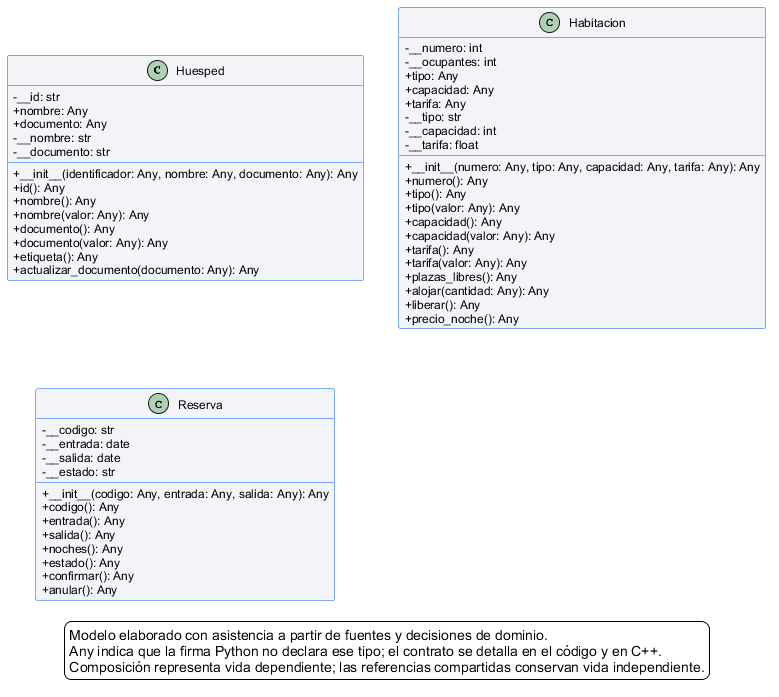

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## resumen informe

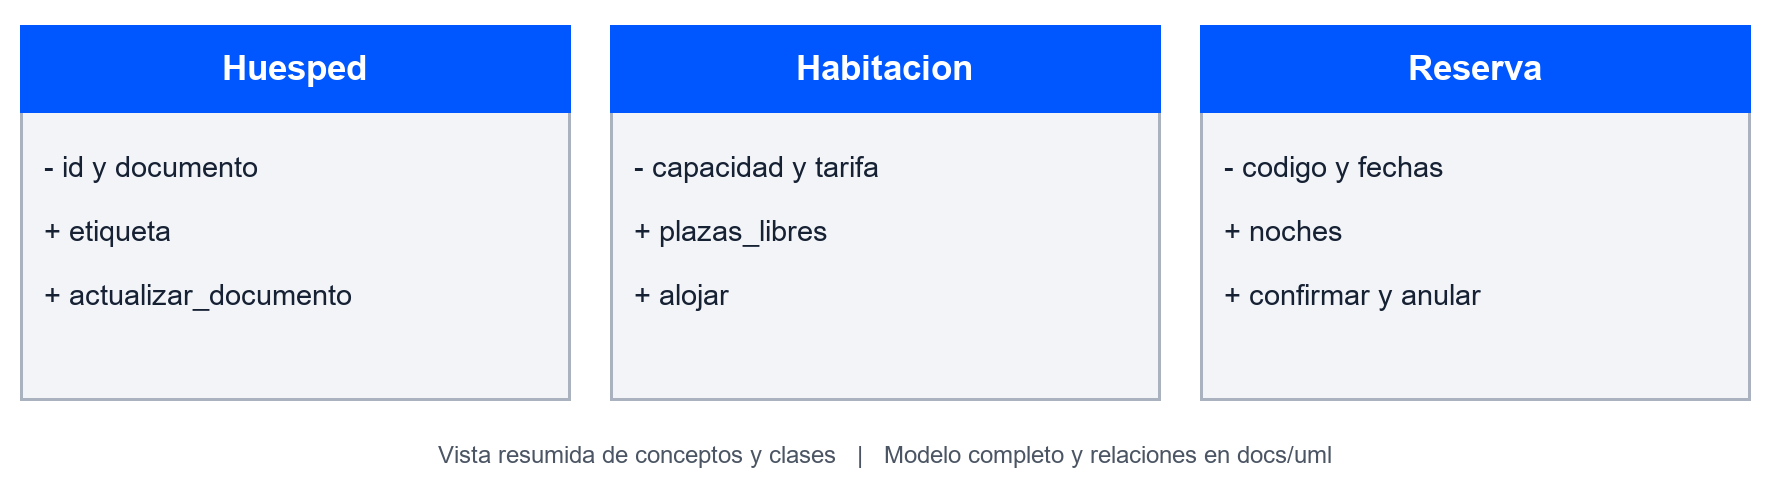

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))
